<a href="https://colab.research.google.com/github/Devaji-Rashmika/Deep_Learning/blob/main/VisionPort_Deep_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

print("PyTorch Version:", torch.__version__)

if torch.cuda.is_available():

    print("GPU Available!")

    print(
        "GPU Name:",
        torch.cuda.get_device_name(0)
    )

else:

    print("GPU Not Available")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected Device:", device)

PyTorch Version: 2.14.1+cu130
GPU Available!
GPU Name: Tesla T4
Selected Device: cuda


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/VisionPort"

folders = [
    "dataset",
    "dataset/train",
    "dataset/validation",
    "dataset/test",
    "models",
    "notebooks",
    "results",
    "preprocessing",
    "documentation"
]

for folder in folders:

    path = os.path.join(PROJECT_PATH, folder)

    os.makedirs(path, exist_ok=True)

    print("Created:", path)

print("\nVisionPort project structure created successfully!")

Created: /content/drive/MyDrive/VisionPort/dataset
Created: /content/drive/MyDrive/VisionPort/dataset/train
Created: /content/drive/MyDrive/VisionPort/dataset/validation
Created: /content/drive/MyDrive/VisionPort/dataset/test
Created: /content/drive/MyDrive/VisionPort/models
Created: /content/drive/MyDrive/VisionPort/notebooks
Created: /content/drive/MyDrive/VisionPort/results
Created: /content/drive/MyDrive/VisionPort/preprocessing
Created: /content/drive/MyDrive/VisionPort/documentation

VisionPort project structure created successfully!


In [ ]:
for root, dirs, files in os.walk(PROJECT_PATH):

    level = root.replace(PROJECT_PATH, "").count(os.sep)

    indent = "    " * level

    print(indent + os.path.basename(root) + "/")

VisionPort/
    dataset/
        train/
        validation/
        test/
    models/
    notebooks/
    results/
    preprocessing/
    documentation/


In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/VisionPort"

print("Does VisionPort folder exist?", os.path.exists(PROJECT_PATH))

for root, dirs, files in os.walk(PROJECT_PATH):
    level = root.replace(PROJECT_PATH, "").count(os.sep)
    indent = "    " * level
    print(indent + os.path.basename(root) + "/")

Does VisionPort folder exist? True
VisionPort/
    dataset/
        train/
        validation/
        test/
    models/
    notebooks/
    results/
    preprocessing/
    documentation/


In [ ]:
import torch
import torchvision
import PIL
import matplotlib

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Pillow:", PIL.__version__)
print("Matplotlib:", matplotlib.__version__)

print("\nDevice:", device)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Pillow: 11.3.0
Matplotlib: 3.10.0

Device: cuda
CUDA available: True


In [ ]:
!pip install -q torch torchvision pillow matplotlib numpy pandas scikit-learn

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torchvision
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

All libraries imported successfully!
PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130


In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/VisionPort"

DATASET_PATH = os.path.join(PROJECT_PATH, "dataset")

for folder in ["train", "validation", "test"]:
    path = os.path.join(DATASET_PATH, folder)

    print(f"\n{folder.upper()} folder:")
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("Contents:", os.listdir(path))


TRAIN folder:
Exists: True
Contents: []

VALIDATION folder:
Exists: True
Contents: []

TEST folder:
Exists: True
Contents: []


In [ ]:
import os
import json

PROJECT_PATH = "/content/drive/MyDrive/VisionPort"

dataset_info = {
    "project": "VisionPort",
    "task_type": "To be confirmed",
    "dataset_source": "To be selected",
    "image_format": ["jpg", "jpeg", "png"],
    "image_size": [224, 224],
    "classes": [],
    "notes": "Dataset details will be updated after reviewing the official project requirements."
}

file_path = os.path.join(PROJECT_PATH, "dataset", "dataset_info.json")

with open(file_path, "w") as file:
    json.dump(dataset_info, file, indent=4)

print("Dataset information file created!")
print("Location:", file_path)

Dataset information file created!
Location: /content/drive/MyDrive/VisionPort/dataset/dataset_info.json


In [ ]:
with open(file_path, "r") as file:
    print(file.read())

{
    "project": "VisionPort",
    "task_type": "To be confirmed",
    "dataset_source": "To be selected",
    "image_format": [
        "jpg",
        "jpeg",
        "png"
    ],
    "image_size": [
        224,
        224
    ],
    "classes": [],
    "notes": "Dataset details will be updated after reviewing the official project requirements."
}


In [ ]:
from PIL import Image
from torchvision import transforms

image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

print("Image preprocessing function is ready!")

Image preprocessing function is ready!


In [ ]:
def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image_tensor = image_transform(image)

    return image_tensor

print("Preprocessing function created successfully!")

Preprocessing function created successfully!


Sample image created: /content/visionport_sample.jpg


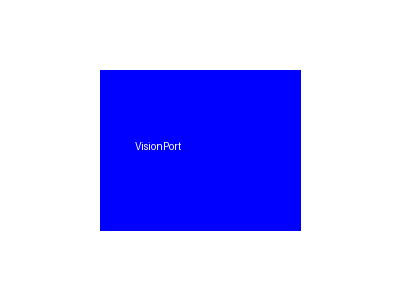

In [ ]:
from PIL import Image, ImageDraw

sample_image = Image.new("RGB", (400, 300), "white")
draw = ImageDraw.Draw(sample_image)

draw.rectangle((100, 70, 300, 230), fill="blue")
draw.text((135, 140), "VisionPort", fill="white")

sample_path = "/content/visionport_sample.jpg"
sample_image.save(sample_path)

print("Sample image created:", sample_path)
display(sample_image)

In [ ]:
processed_image = preprocess_image(sample_path)

print("Original image size:", sample_image.size)
print("Processed tensor shape:", processed_image.shape)
print("Tensor data type:", processed_image.dtype)

Original image size: (400, 300)
Processed tensor shape: torch.Size([3, 224, 224])
Tensor data type: torch.float32


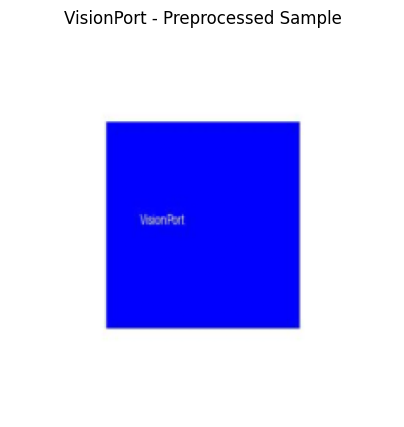

In [ ]:
import matplotlib.pyplot as plt

image_to_display = processed_image.permute(1, 2, 0).numpy()

plt.figure(figsize=(5, 5))
plt.imshow(image_to_display)
plt.title("VisionPort - Preprocessed Sample")
plt.axis("off")
plt.show()

In [ ]:
print("Minimum pixel value:", processed_image.min().item())
print("Maximum pixel value:", processed_image.max().item())
print("Tensor shape:", processed_image.shape)

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Tensor shape: torch.Size([3, 224, 224])


In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/VisionPort/dataset"

for split in ["train", "validation", "test"]:
    split_path = os.path.join(DATASET_PATH, split)

    print(f"\n{split.upper()}")

    if os.path.exists(split_path):
        for class_name in os.listdir(split_path):
            class_path = os.path.join(split_path, class_name)

            if os.path.isdir(class_path):
                count = len([
                    f for f in os.listdir(class_path)
                    if f.lower().endswith((".jpg", ".jpeg", ".png"))
                ])

                print(class_name, ":", count, "images")
    else:
        print("Folder not found")


TRAIN

VALIDATION

TEST


In [ ]:
import os

def check_dataset(dataset_path):

    splits = ["train", "validation", "test"]
    extensions = (".jpg", ".jpeg", ".png")

    for split in splits:

        split_path = os.path.join(dataset_path, split)

        print("\nChecking:", split)

        if not os.path.exists(split_path):
            print("Folder missing!")
            continue

        class_folders = [
            name for name in os.listdir(split_path)
            if os.path.isdir(os.path.join(split_path, name))
        ]

        if not class_folders:
            print("No class folders found!")

        for class_name in class_folders:

            class_path = os.path.join(split_path, class_name)

            images = [
                f for f in os.listdir(class_path)
                if f.lower().endswith(extensions)
            ]

            print(class_name, ":", len(images), "images")

    print("\nDataset check completed!")

In [ ]:
check_dataset(DATASET_PATH)


Checking: train
No class folders found!

Checking: validation
No class folders found!

Checking: test
No class folders found!

Dataset check completed!


In [ ]:
import os
import pandas as pd

def dataset_summary(dataset_path):

    records = []
    extensions = (".jpg", ".jpeg", ".png")

    for split in ["train", "validation", "test"]:

        split_path = os.path.join(dataset_path, split)

        if not os.path.exists(split_path):
            continue

        for class_name in os.listdir(split_path):

            class_path = os.path.join(split_path, class_name)

            if not os.path.isdir(class_path):
                continue

            image_count = sum(
                1 for file in os.listdir(class_path)
                if file.lower().endswith(extensions)
            )

            records.append({
                "Dataset Split": split,
                "Class": class_name,
                "Image Count": image_count
            })

    return pd.DataFrame(records)

In [ ]:
summary = dataset_summary(DATASET_PATH)

display(summary)

""


In [ ]:
!pip install -q ultralytics

In [ ]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("YOLO installation successful!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.208
YOLO installation successful!


In [ ]:
from ultralytics import YOLO

# Load pretrained YOLO26 Nano model
model = YOLO("yolo26n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!


In [ ]:
print("Available detection classes:\n")

for class_id, class_name in model.names.items():
    print(class_id, ":", class_name)

Available detection classes:

0 : person
1 : bicycle
2 : car
3 : motorcycle
4 : airplane
5 : bus
6 : train
7 : truck
8 : boat
9 : traffic light
10 : fire hydrant
11 : stop sign
12 : parking meter
13 : bench
14 : bird
15 : cat
16 : dog
17 : horse
18 : sheep
19 : cow
20 : elephant
21 : bear
22 : zebra
23 : giraffe
24 : backpack
25 : umbrella
26 : handbag
27 : tie
28 : suitcase
29 : frisbee
30 : skis
31 : snowboard
32 : sports ball
33 : kite
34 : baseball bat
35 : baseball glove
36 : skateboard
37 : surfboard
38 : tennis racket
39 : bottle
40 : wine glass
41 : cup
42 : fork
43 : knife
44 : spoon
45 : bowl
46 : banana
47 : apple
48 : sandwich
49 : orange
50 : broccoli
51 : carrot
52 : hot dog
53 : pizza
54 : donut
55 : cake
56 : chair
57 : couch
58 : potted plant
59 : bed
60 : dining table
61 : toilet
62 : tv
63 : laptop
64 : mouse
65 : remote
66 : keyboard
67 : cell phone
68 : microwave
69 : oven
70 : toaster
71 : sink
72 : refrigerator
73 : book
74 : clock
75 : vase
76 : scissors
77 : te

In [ ]:
import os
import shutil

MODEL_PATH = "/content/drive/MyDrive/VisionPort/models"

os.makedirs(MODEL_PATH, exist_ok=True)

shutil.copy("yolo26n.pt", os.path.join(MODEL_PATH, "yolo26n.pt"))

print("Model saved in Google Drive!")

Model saved in Google Drive!


In [ ]:
!wget -q https://ultralytics.com/images/bus.jpg -O /content/visionport_test.jpg

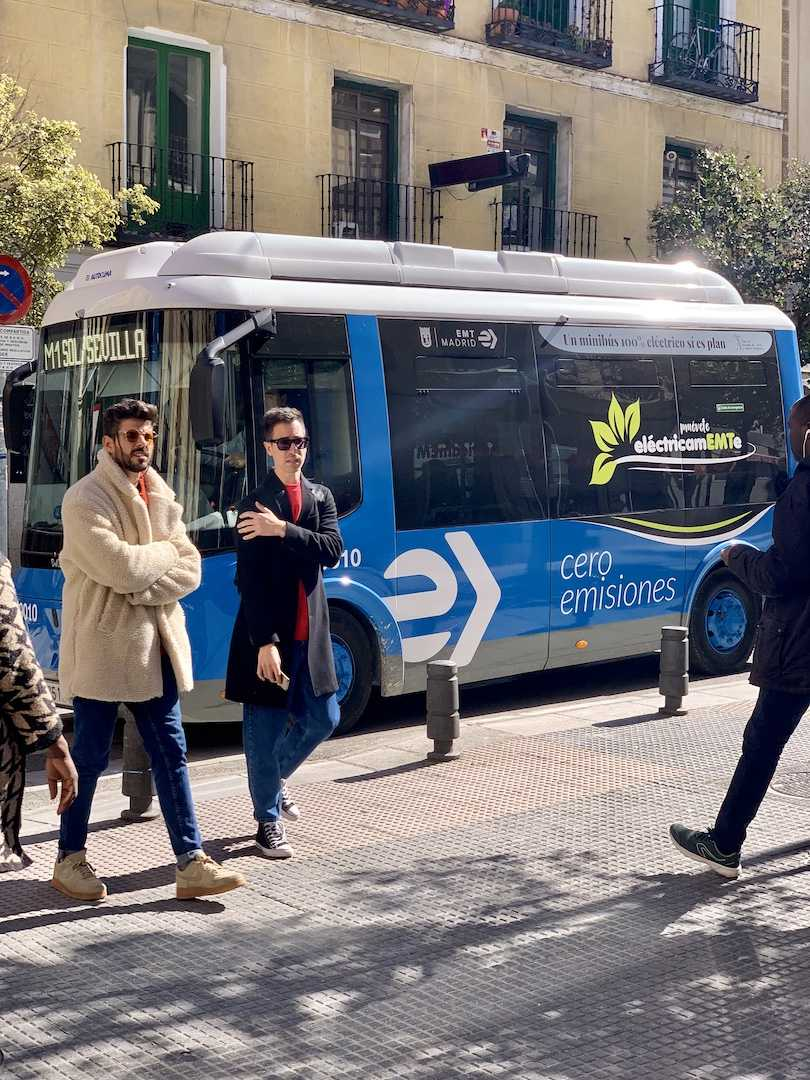

Image size: (810, 1080)
Image loaded successfully!


In [ ]:
from PIL import Image
from IPython.display import display

test_image = Image.open("/content/visionport_test.jpg")

display(test_image)

print("Image size:", test_image.size)
print("Image loaded successfully!")

In [ ]:
# Run YOLO object detection
results = model.predict(
    source="/content/visionport_test.jpg",
    conf=0.25,
    save=True
)

print("Detection completed successfully!")


image 1/1 /content/visionport_test.jpg: 640x480 4 persons, 1 bus, 9.5ms
Speed: 224.4ms preprocess, 9.5ms inference, 21.5ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict
Detection completed successfully!


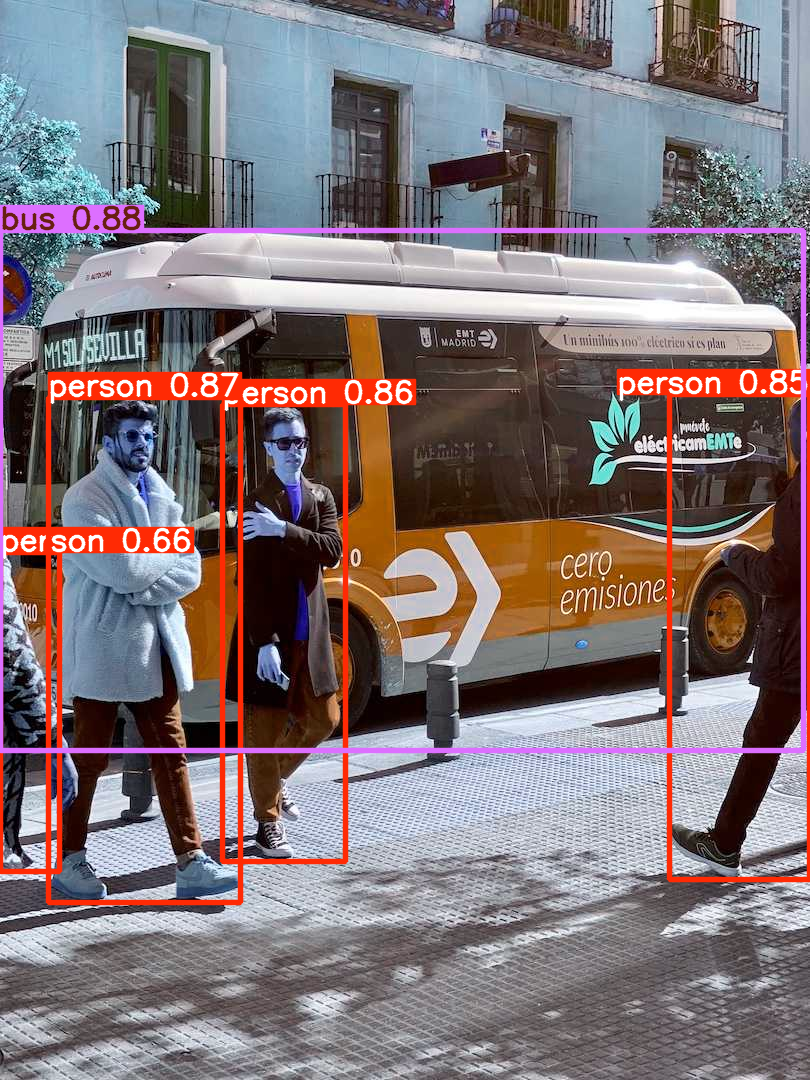


Detected objects:
bus Confidence: 88.06 %
person Confidence: 87.2 %
person Confidence: 86.08 %
person Confidence: 84.62 %
person Confidence: 65.62 %


In [ ]:
from IPython.display import display
from PIL import Image

result_image = results[0].plot()

display(Image.fromarray(result_image))

print("\nDetected objects:")

for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        model.names[class_id],
        "Confidence:",
        round(confidence * 100, 2),
        "%"
    )

In [ ]:
target_classes = [
    "car",
    "motorcycle",
    "bus",
    "truck",
    "bicycle",
    "traffic light"
]

print("VISIONPORT TARGET OBJECTS")
print("-------------------------")

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]

    if class_name in target_classes:
        confidence = float(box.conf[0])

        print(
            f"Object: {class_name} | "
            f"Confidence: {confidence * 100:.2f}%"
        )

VISIONPORT TARGET OBJECTS
-------------------------
Object: bus | Confidence: 88.06%


In [ ]:
from collections import Counter

detected_objects = []

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]

    if class_name in target_classes:
        detected_objects.append(class_name)

object_counts = Counter(detected_objects)

print("VISIONPORT DETECTION SUMMARY")
print("----------------------------")

for name in target_classes:
    print(f"{name}: {object_counts.get(name, 0)}")

print("----------------------------")
print("Total target objects:", len(detected_objects))

VISIONPORT DETECTION SUMMARY
----------------------------
car: 0
motorcycle: 0
bus: 1
truck: 0
bicycle: 0
traffic light: 0
----------------------------
Total target objects: 1


In [ ]:
import os
from PIL import Image
from IPython.display import display

traffic_light_path = "/content/traffic_light_crops"
os.makedirs(traffic_light_path, exist_ok=True)

traffic_count = 0

for i, box in enumerate(results[0].boxes):

    class_id = int(box.cls[0])
    class_name = model.names[class_id]

    if class_name == "traffic light":

        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

        cropped_image = test_image.crop((x1, y1, x2, y2))

        crop_path = os.path.join(
            traffic_light_path,
            f"traffic_light_{i}.jpg"
        )

        cropped_image.save(crop_path)

        print("Traffic light saved:", crop_path)
        display(cropped_image)

        traffic_count += 1

print("Total traffic lights cropped:", traffic_count)

Total traffic lights cropped: 0


In [ ]:
import os
from PIL import Image

RESULTS_PATH = "/content/drive/MyDrive/VisionPort/results"

os.makedirs(RESULTS_PATH, exist_ok=True)

# Generate annotated detection image
annotated_image = results[0].plot()

# Save image
output_path = os.path.join(
    RESULTS_PATH,
    "vehicle_detection_result.jpg"
)

Image.fromarray(annotated_image).save(output_path)

print("Detection result saved successfully!")
print("Location:", output_path)

Detection result saved successfully!
Location: /content/drive/MyDrive/VisionPort/results/vehicle_detection_result.jpg


Saved image size: (810, 1080)


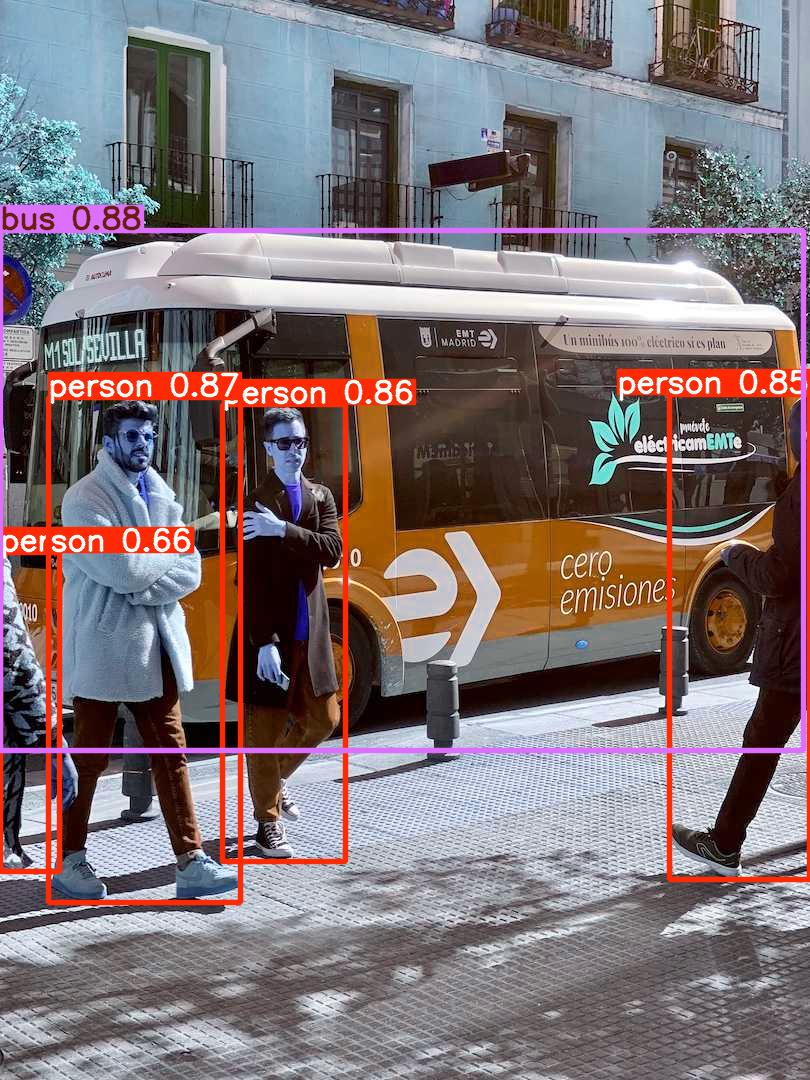

In [ ]:
saved_image = Image.open(output_path)

print("Saved image size:", saved_image.size)
display(saved_image)

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Screenshot 2026-11-10 091506.png to Screenshot 2026-11-10 091506.png



image 1/1 /content/Screenshot 2026-11-10 091506.png: 352x640 3 persons, 1 bus, 24.2ms
Speed: 1.7ms preprocess, 24.2ms inference, 1.6ms postprocess per image at shape (1, 3, 352, 640)


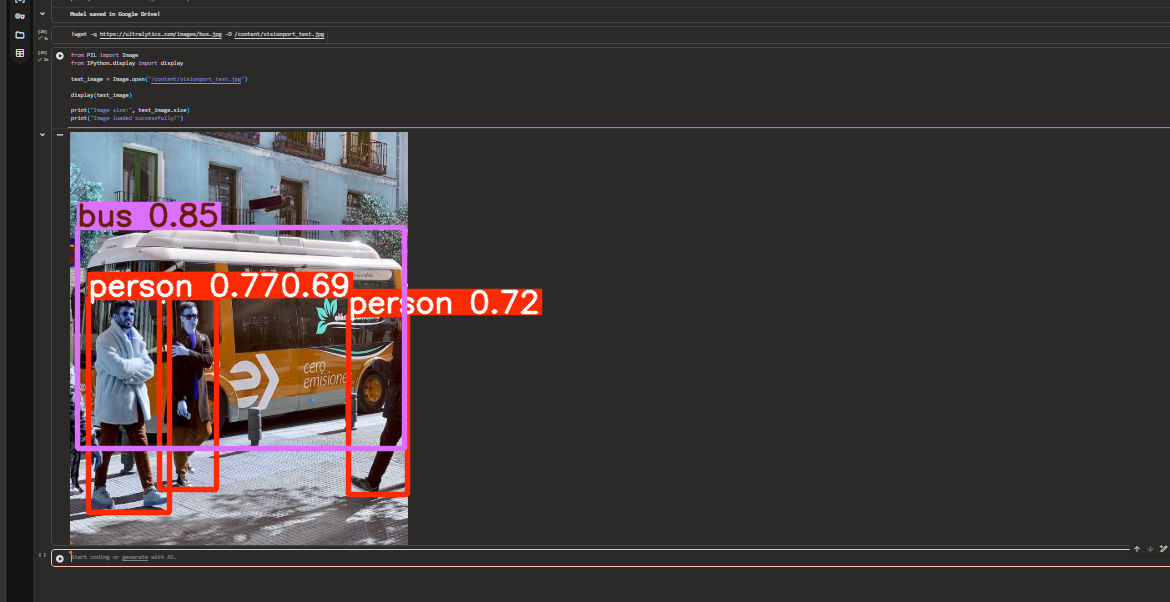

In [ ]:
from ultralytics import YOLO
from PIL import Image
from IPython.display import display

image_path = list(uploaded.keys())[0]

traffic_results = model.predict(
    source=image_path,
    conf=0.20
)

display(Image.fromarray(traffic_results[0].plot()))